# Hipótesis 1: Solidez, Eficiencia Defensiva y Búsqueda de Talentos Ocultos

**La Hipótesis:**
En el mercado futbolístico actual, el valor y la percepción de un jugador de corte defensivo suelen estar fuertemente condicionados por la clasificación general de su equipo. Sin embargo, nuestra hipótesis plantea que **existen "talentos ocultos" en equipos de la zona media y baja de la tabla (Cuartiles 1 y 2) cuyo rendimiento táctico y eficiencia individual es igual o superior al de jugadores de equipos de élite (Cuartil 4).**

Un alto volumen de acciones defensivas (entradas e intercepciones) no siempre es sinónimo de calidad si va acompañado de un excesivo riesgo disciplinario (faltas y tarjetas). Por lo tanto, aislando la métrica de "limpieza defensiva" y midiendo el impacto neto colectivo del jugador cuando está en el campo (+/- por 90 minutos), podemos detectar perfiles de alta fiabilidad que se encuentran severamente infravalorados en el mercado.

**¿Qué vamos a llevar a cabo en este análisis?**
Para validar esta hipótesis y encontrar estos perfiles, estructuraremos el análisis en los siguientes pasos:

1. **Extracción y Cruce de Datos:** Uniremos el rendimiento detallado de la temporada 2025/2026 (métricas de FBref) con los valores de mercado económicos actuales (Transfermarkt) utilizando consultas SQL en memoria mediante DuckDB.
2. **Filtrado de Fiabilidad y Demarcación:** Aislaremos a los perfiles encargados de la contención (Defensas y Mediocentros), exigiendo un mínimo de 1.000 minutos jugados para evitar ruido estadístico o "falsos positivos".
3. **Contextualización por Cuartiles:** Clasificaremos a todos los equipos de la liga en 4 niveles de rendimiento (del Q4 Élite al Q1 Zona Baja) para evaluar si un jugador destaca por sí mismo a pesar de estar en un ecosistema perdedor.
4. **Cálculo de Métricas Ponderadas (p/90):** Normalizaremos todo el volumen defensivo por cada 90 minutos jugados y calcularemos nuestro KPI principal: el **Ratio de Limpieza** (Entradas con éxito por cada falta cometida).
5. **Análisis Visual de Interrelación:** A través de modelado gráfico interactivo, cruzaremos variables tácticas (Ej: *Anticipación vs. Choque*, *Volumen Defensivo vs. Impacto Colectivo*) para perfilar matemáticamente a los jugadores y extraer directamente a los líderes de cada métrica.

## 1. Configuración y Extracción Inicial de Datos (Hipótesis 1)
En este primer bloque se establecen las bases para el análisis defensivo. Se utiliza `duckdb` para hacer una extracción rápida y eficiente de los datos almacenados en CSV. El objetivo es cruzar la información de rendimiento de cada jugador en la temporada 2025/2026 con su valor de mercado más reciente.

In [1]:
import pandas as pd
import duckdb
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

extract_dir = 'dataset_transfermarkt'
liga_filtro = 'ES1'  # Filtramos por La Liga como ejemplo

# Conexión a DuckDB y extracción de datos cruzados
con = duckdb.connect(':memory:')
query = f"""
WITH UltimoValor AS (
    SELECT player_id, market_value_in_eur
    FROM read_csv_auto('{extract_dir}/player_valuations.csv')
    QUALIFY ROW_NUMBER() OVER(PARTITION BY player_id ORDER BY date DESC) = 1
),
EstadisticasTemporadas AS (
    SELECT 
        player_id,
        SUM(CASE WHEN date BETWEEN '2025-07-01' AND '2026-06-30' THEN minutes_played ELSE 0 END) AS min_25_26,
        SUM(CASE WHEN date BETWEEN '2025-07-01' AND '2026-06-30' THEN goals ELSE 0 END) AS goles_25_26,
        SUM(CASE WHEN date BETWEEN '2025-07-01' AND '2026-06-30' THEN assists ELSE 0 END) AS asis_25_26
    FROM read_csv_auto('{extract_dir}/appearances.csv')
    WHERE date BETWEEN '2025-07-01' AND '2026-06-30'
    GROUP BY player_id
)
SELECT 
    p.player_id, 
    p.name AS nombre, 
    p.date_of_birth AS fecha_nacimiento, 
    p.position AS posicion, 
    p.sub_position AS sub_posicion,
    p.foot AS pie_dominante,        
    p.height_in_cm AS altura_cm,    
    p.contract_expiration_date AS fin_contrato, 
    c.domestic_competition_id AS liga, 
    c.name AS club, 
    v.market_value_in_eur AS valor_mercado, 
    e.* EXCLUDE(player_id)
FROM read_csv_auto('{extract_dir}/players.csv') p
JOIN UltimoValor v ON p.player_id = v.player_id
JOIN EstadisticasTemporadas e ON p.player_id = e.player_id
LEFT JOIN read_csv_auto('{extract_dir}/clubs.csv') c ON p.current_club_id = c.club_id
WHERE v.market_value_in_eur IS NOT NULL
"""
df_base = con.execute(query).df()
print(f"Total de registros base extraídos: {len(df_base)}")

Total de registros base extraídos: 8433


## 2. Incorporación de Estadísticas Detalladas de FBREF
Dado que el archivo principal a veces carece de métricas defensivas avanzadas, cargamos el archivo secundario con datos de FBREF (`players_data-2025_2026.csv`). Filtramos por la competición deseada (ej. 'es La Liga') y procedemos a calcular el valor de mercado para cada jugador basándonos en un cruce de nombres (utilizando limpieza de cadenas y un diccionario de alias).

In [2]:
import unicodedata
import re

def clean_name(name):
    if pd.isna(name): return ""
    name_str = str(name).strip().lower()
    name_str = ''.join(c for c in unicodedata.normalize('NFD', name_str) if unicodedata.category(c) != 'Mn')
    name_str = re.sub(r'[^\w\s]', ' ', name_str)
    return re.sub(r'\s+', ' ', name_str).strip()

# Diccionario de alias para cruzar FBREF y Transfermarkt
alias_map = {
    'gabriel magalhaes': 'gabriel', 'max kilman': 'maximilian kilman', 'hwang hee chan': 'hee chan hwang',
    'toti gomes': 'toti', 'idrissa gana gueye': 'idrissa gueye', 'nicolas gonzalez': 'nico gonzalez',
    'emi buendia': 'emiliano buendia', 'hannibal mejbri': 'hannibal', 'yeremi pino': 'yeremy pino',
    'valentino livramento': 'tino livramento', 'nico o reilly': 'nico o reilly', 'eli junior kroupi': 'junior kroupi',
    'yehor yarmoliuk': 'yegor yarmolyuk', 'daniel ballard': 'dan ballard', 'florentino luis': 'florentino',
    'ferdi kadioglu': 'ferdi kadioglu', 'lucas': 'lucas', 'adam smith': 'adam smith', 'castrin': 'castrin',
    'roberto navarro': 'robert navarro', 'domingos andre ribeiro almeida': 'andre almeida',
    'joaquin martinez gauna': 'quique salas', 'djene': 'dakonam djene', 'iglesias': 'juan iglesias',
    'olasagasti': 'jon ander olasagasti', 'francisco perez': 'fran perez', 'catena': 'alejandro catena',
    'isaac palazon camacho': 'isi palazon', 'jose luis garcia vaya': 'pepelu', 'urko gonzalez': 'urko gonzalez de zarate',
    'brugui': 'roger brugue', 'copete': 'jose copete', 'rahim bonkano': 'abdel rahim alhassane',
    'lucas ahijado': 'lucas ahijado', 'andre frank zambo anguissa': 'frank anguissa', 'oliver nielsen': 'oliver nielsen',
    'albert gudmundsson': 'albert gudmundsson', 'rafel obrador': 'rafa obrador', 'leo skiri ostigard': 'leo ostigard',
    'ze pedro figueiredo': 'ze pedro', 'michel ndary adopo': 'michel adopo', 'kialonda': 'kialonda gaspar',
    'oliver jensen': 'oliver jensen', 'romano floriani': 'romano floriani mussolini', 'castrop jens': 'jens castrop',
    'ifechukwu ogbus': 'ifechukwu ogbus', 'caio henrique oliveira silva': 'caio henrique', 'igor carioca': 'igor silva',
    'dehmaime assoumani': 'dehmaine assoumani', 'abdulai juma bah': 'abdulai juma bah'
}

df_full_fbref = pd.read_csv('dataset_transfermarkt/players_data-2025_2026.csv')
df_liga_fbref = df_full_fbref[df_full_fbref['Comp'] == 'es La Liga'].copy()

df_base['nombre_clean'] = df_base['nombre'].apply(clean_name)
df_liga_fbref['Player_clean_FB'] = df_liga_fbref['Player'].apply(clean_name).replace(alias_map)
df_liga_fbref['Born_FB'] = pd.to_numeric(df_liga_fbref['Born'], errors='coerce')
df_base['Born_TM'] = pd.to_datetime(df_base['fecha_nacimiento'], errors='coerce').dt.year
df_base['Market_Value_M'] = df_base['valor_mercado'] / 1_000_000.0

def find_market_value(row):
    matches = df_base[df_base['nombre_clean'] == row['Player_clean_FB']]
    if matches.empty: return -1.0
    elif len(matches) == 1: return matches.iloc[0]['Market_Value_M']
    else:
        if pd.notna(row['Born_FB']):
            for _, match in matches.iterrows():
                if pd.notna(match['Born_TM']) and abs(match['Born_TM'] - row['Born_FB']) <= 1:
                    return match['Market_Value_M']
        return matches['Market_Value_M'].max()

df_liga_fbref['Market_Value_M'] = df_liga_fbref.apply(find_market_value, axis=1)
print(f"Jugadores de La Liga emparejados: {len(df_liga_fbref)}")

Jugadores de La Liga emparejados: 611


## 3. Clasificación de Equipos y Filtrado Defensivo
Para contextualizar el rendimiento individual con el éxito del equipo, calculamos una tabla de clasificación (posiciones en cuartiles) basándonos en los puntos (Victorias * 3 + Empates). Luego, filtramos el dataset para quedarnos únicamente con los Mediocentros y Defensas, aplicando restricciones de minutos mínimos (1000 min), edad máxima (35 años) y valor de mercado (<= 200 M€).

In [3]:
# Calcular posición en la tabla
team_stats = df_liga_fbref.groupby('Squad').agg({'W': 'max', 'D': 'max', 'L': 'max'}).reset_index()
team_stats['Points'] = team_stats['W'] * 3 + team_stats['D']
team_stats['Position'] = team_stats['Points'].rank(ascending=False, method='min')

df_liga_pos = pd.merge(df_liga_fbref, team_stats[['Squad', 'Position']], on='Squad', how='left')

# Quedarnos solo con defensas y mediocentros
df_def_mf = df_liga_pos[~df_liga_pos['Pos'].str.contains('GK', na=False) & (df_liga_pos['Pos'].str.contains('MF|DF', na=False))].copy()

def clasificar_jugador(pos):
    if 'DF' in pos and 'MF' not in pos: return 'Defensa Puro (DF)'
    elif 'DF' in pos and 'MF' in pos: return 'Mediocentro / Defensivo (MF,DF)'
    elif 'FW' in pos: return 'Mediocentro / Ofensivo (MF,FW)'
    else: return 'Mediocentro / Puro (MF)'
        
df_def_mf['Tipo_Demarcacion'] = df_def_mf['Pos'].apply(clasificar_jugador)

# Filtros base (se pueden ajustar)
edad_maxima_def = 35
valor_mercado_max = 200.0

df_def_mf['edad_final'] = pd.to_numeric(df_def_mf['Age'], errors='coerce').fillna(25)
df_def_mf['valor_mercado_num'] = df_def_mf['Market_Value_M'].fillna(-1.0)

df_def_mf = df_def_mf[(df_def_mf['Min'] >= 1000) & 
                      (df_def_mf['edad_final'] <= edad_maxima_def) & 
                      ((df_def_mf['valor_mercado_num'] == -1.0) | (df_def_mf['valor_mercado_num'] <= valor_mercado_max))].copy()

print(f"Jugadores tras filtros defensivos: {len(df_def_mf)}")

Jugadores tras filtros defensivos: 263


## 4. Cálculo de Métricas Ponderadas por 90 Minutos y Clasificación en Cuartiles
Convertimos los valores absolutos en métricas ajustadas por 90 minutos (Entradas ganadas, Intercepciones, Centros). También calculamos el 'Ratio de Limpieza' (Entradas divididas entre Faltas) y el total de tarjetas. Asignamos a cada jugador un cuartil de rendimiento basado en la clasificación de su equipo.

In [4]:
orden_cuartiles = ['4 (Zona Alta)', '3 (Media-Alta)', '2 (Media-Baja)', '1 (Zona Baja)']

df_def_mf['Tabla_Cuartil'] = pd.qcut(df_def_mf['Position'], 4, labels=orden_cuartiles)
df_def_mf['Tabla_Cuartil'] = pd.Categorical(df_def_mf['Tabla_Cuartil'], categories=orden_cuartiles, ordered=True)

# Evitar divisiones por cero
df_def_mf['90s'] = df_def_mf['90s'].replace(0, np.nan)
df_def_mf['Fls'] = df_def_mf['Fls'].replace(0, 0.1) 

# Métricas derivadas
df_def_mf['Entradas_p90'] = (df_def_mf['TklW'] / df_def_mf['90s']).round(2)
df_def_mf['Intercepciones_p90'] = (df_def_mf['Int'] / df_def_mf['90s']).round(2)
df_def_mf['Ratio_Limpieza'] = (df_def_mf['TklW'] / df_def_mf['Fls']).round(2)
df_def_mf['Centros_p90'] = (df_def_mf['Crs'] / df_def_mf['90s']).round(2) if 'Crs' in df_def_mf.columns else 0.0
df_def_mf['Tarjetas_Totales'] = df_def_mf['CrdY'].fillna(0) + df_def_mf['CrdR'].fillna(0)

# Extraer métrica de impacto on-off (Plus/Minus)
col_impacto = '+/-90' if '+/-90' in df_def_mf.columns else ([c for c in df_def_mf.columns if '90' in c and ('+/-' in c or 'plus' in c.lower())] + [None])[0]
df_def_mf['Impacto_+/-90'] = df_def_mf[col_impacto] if col_impacto else 0.0

# Descartar jugadores con métricas clave nulas
df_def_mf = df_def_mf.dropna(subset=['Entradas_p90', 'Intercepciones_p90', 'Ratio_Limpieza']).copy()

print("Métricas calculadas con éxito.")
display(df_def_mf[['Player', 'Squad', 'Tabla_Cuartil', 'Entradas_p90', 'Ratio_Limpieza', 'Impacto_+/-90']].head())

Métricas calculadas con éxito.


,Player,Squad,Tabla_Cuartil,Entradas_p90,Ratio_Limpieza,Impacto_+/-90
2,Abdel Abqar,Getafe,3 (Media-Alta),1.06,0.57,0.06
5,David Affengruber,Elche,1 (Zona Baja),1.52,1.47,-0.12
7,Lucien Agoume,Sevilla,2 (Media-Baja),1.34,0.69,-0.30
9,Marc Aguado,Elche,1 (Zona Baja),0.94,1.04,-0.22
12,Lucas Ahijado,Oviedo,1 (Zona Baja),2.38,2.07,-1.31


## 5. Visualización: Análisis de Entradas vs Limpieza Defensiva
Visualizamos la relación entre la cantidad de robos directos (Entradas por 90') y el Ratio de Limpieza (Entradas por cada Falta cometida). Esto permite identificar perfiles proactivos pero disciplinados, separándolos de aquellos que recurren excesivamente a la infracción.

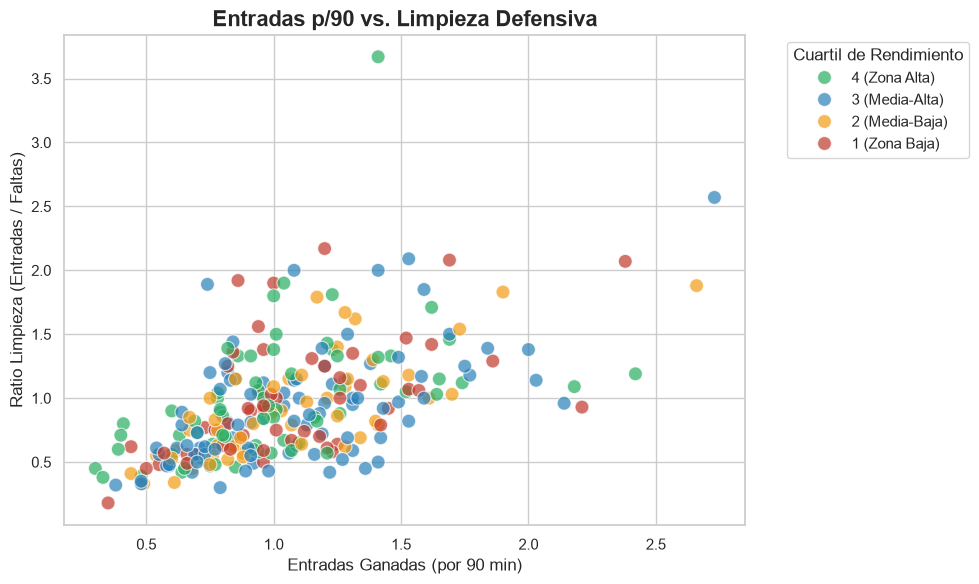

In [5]:
mapa_colores_cuartil = {
    '4 (Zona Alta)': '#27ae60',   # Verde 
    '3 (Media-Alta)': '#2980b9',  # Azul 
    '2 (Media-Baja)': '#f39c12',  # Naranja
    '1 (Zona Baja)': '#c0392b'    # Rojo 
}

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_def_mf, x='Entradas_p90', y='Ratio_Limpieza', hue='Tabla_Cuartil', 
                palette=mapa_colores_cuartil, s=100, alpha=0.7)

plt.title('Entradas p/90 vs. Limpieza Defensiva', fontsize=16, fontweight='bold')
plt.xlabel('Entradas Ganadas (por 90 min)', fontsize=12)
plt.ylabel('Ratio Limpieza (Entradas / Faltas)', fontsize=12)
plt.legend(title='Cuartil de Rendimiento', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Agrupación y Generación de Tablas de Medias por Cuartil
Para entender mejor las tendencias, definimos una función que agrupa a los jugadores por Cuartil, calcula la media de una métrica específica, e identifica a los 3 mejores jugadores (Top 3) de cada cuartil. A continuación, mostramos la tabla de impacto (Plus/Minus) y su correspondiente gráfico de barras agregadas.

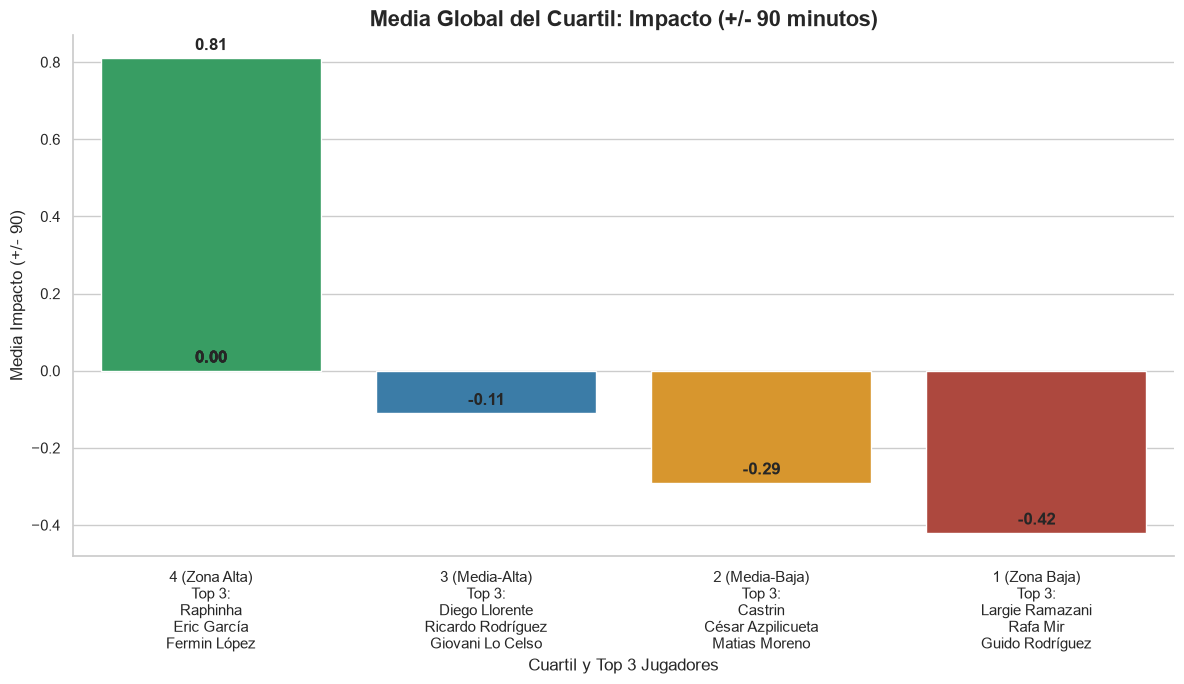

In [6]:
def preparar_datos_metrica(df, col_metrica, col_orden):
    df_ordenado = df.sort_values(by=['Tabla_Cuartil', col_orden], ascending=[False, False])
    # Agrupar nombres para la leyenda del eje X
    top3_nombres = df_ordenado.groupby(['Tabla_Cuartil'], observed=False)['Player'].apply(lambda x: '\n'.join(x.head(3))).reset_index(name='Top3_Nombres')
    media_cuartil = df.groupby(['Tabla_Cuartil'], observed=False).agg(Media_Valor=(col_metrica, 'mean')).reset_index()
    
    df_final = pd.merge(media_cuartil, top3_nombres, on=['Tabla_Cuartil'])
    df_final['Media_Valor'] = df_final['Media_Valor'].round(2)
    df_final['Eje_X_Label'] = df_final['Tabla_Cuartil'].astype(str) + '\nTop 3:\n' + df_final['Top3_Nombres']
    df_final['Tabla_Cuartil'] = pd.Categorical(df_final['Tabla_Cuartil'], categories=orden_cuartiles, ordered=True)
    return df_final.sort_values('Tabla_Cuartil')

# Calcular medias para el Impacto (+/- 90)
df_imp_medias = preparar_datos_metrica(df_def_mf, 'Impacto_+/-90', 'Impacto_+/-90')

plt.figure(figsize=(12, 7))
ax = sns.barplot(data=df_imp_medias, x='Eje_X_Label', y='Media_Valor', hue='Tabla_Cuartil', palette=mapa_colores_cuartil, dodge=False)

plt.title('Media Global del Cuartil: Impacto (+/- 90 minutos)', fontsize=16, fontweight='bold')
plt.xlabel('Cuartil y Top 3 Jugadores', fontsize=12)
plt.ylabel('Media Impacto (+/- 90)', fontsize=12)

# Añadir los valores sobre las barras
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 9), 
                textcoords = 'offset points',
                fontweight='bold')

plt.legend([],[], frameon=False) # Ocultar leyenda redundante
sns.despine()
plt.tight_layout()
plt.show()